## Imports and Files

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
cmu_men_path = "data/carnegie_mellon_men.csv"
cmu_women_path = "data/carnegie_mellon_women.csv"
d3_data_path = "data/d3_data.csv"


In [3]:
cmu_men = pd.read_csv(cmu_men_path)
cmu_women = pd.read_csv(cmu_women_path)
d3_data = pd.read_csv(d3_data_path, low_memory=False)

## EDA

## Data Cleaning


In [4]:
# ---- Cleaning policy (all thresholds in one place, tunable) ----
VALID_PARS = [3, 4, 5]
MAX_OVER_PAR = 15                       # a single hole can't realistically exceed par + this many strokes
ACE_ONLY_PAR = 3                        # a hole-in-one (score 1) is only realistic on a par 3
YARDAGE_BOUNDS = {                      # physically plausible hole length by par (yards)
    3: (70, 300), 4: (180, 560), 5: (200, 720),
}
OUTCOME_ORDER = ["eagle+", "birdie", "par", "bogey", "double+"]


def _outcomes(to_par):
    """Vectorized to-par -> outcome label."""
    return np.select(
        [to_par <= -2, to_par == -1, to_par == 0, to_par == 1, to_par >= 2],
        OUTCOME_ORDER, default="other")


def data_quality_audit(df):
    """Report each corruption source (does NOT mutate). Returns a small DataFrame."""
    n = len(df)
    checks = {
        "score == 0  (DNF / no-card placeholder)":        int((df["score"] == 0).sum()),
        "par not in {3,4,5}  (summary row)":              int((~df["par"].isin(VALID_PARS)).sum()),
        f"score > par + {MAX_OVER_PAR}  (impossible hole)":   int((df["score"] > df["par"] + MAX_OVER_PAR).sum()),
        f"score == 1 on par > {ACE_ONLY_PAR}  (implausible hole-in-one)": int(((df["score"] == 1) & (df["par"] > ACE_ONLY_PAR)).sum()),
        "score - par != to_par  (internal contradiction)": int((df["score"] - df["par"] != df["to_par"]).sum()),
    }
    rep = pd.DataFrame({"n_rows": pd.Series(checks)})
    rep["pct"] = (rep["n_rows"] / n * 100).round(4)
    return rep


def scoring_summary(df):
    """Headline aggregates used for the before/after validation. All outputs are small."""
    rates = (pd.Series(_outcomes(df["to_par"].to_numpy()))
             .value_counts(normalize=True).reindex(OUTCOME_ORDER) * 100).round(3)
    by_par = df.groupby("par")["to_par"].agg(["mean", "std", "size"]).round(3)
    r = (df[df["score"] > 0]
         .groupby(["tournament_id", "round_number", "player_id"])
         .agg(holes=("score", "size"), to_par=("to_par", "sum")))
    r = r.loc[r["holes"] == 18, "to_par"]
    rnd = pd.Series({"mean": round(r.mean(), 3), "median": r.median(),
                     "min": r.min(), "max": r.max(), "n_rounds": len(r)})
    return {"outcome_rates": rates, "by_par": by_par, "round": rnd}


def clean_d3(df):
    """Apply the documented cleaning policy. Idempotent and non-destructive to valid scores."""
    df = df.drop(columns=["course_name"], errors="ignore")   # 5. dead column

    keep = (                                                  # 1-3. structurally-invalid rows
        (df["score"] > 0)
        & df["par"].isin(VALID_PARS)
        & (df["score"] <= df["par"] + MAX_OVER_PAR)
        & ~((df["score"] == 1) & (df["par"] > ACE_ONLY_PAR))  # implausible ace on par 4/5
    )
    df = df[keep].copy()

    bad_yardage = pd.Series(False, index=df.index)            # 4. implausible distance -> NaN
    for p, (lo, hi) in YARDAGE_BOUNDS.items():
        bad_yardage |= (df["par"] == p) & ~df["yardage"].between(lo, hi)
    df.loc[bad_yardage, "yardage"] = np.nan
    return df


# ---- Run it: audit -> capture "before" -> clean -> log ----
print("Data-quality audit (raw):")
print(data_quality_audit(d3_data).to_string(), "\n")

before_summary = scoring_summary(d3_data)     # small snapshot for validation (no full copy)
n_before = len(d3_data)

d3_data = clean_d3(d3_data)

n_after = len(d3_data)
print(f"Dropped {n_before - n_after:,} rows ({(n_before - n_after) / n_before * 100:.3f}%)"
      f"  ->  {n_after:,} rows remain")
print(f"yardage values set to NaN (implausible for their par): {d3_data['yardage'].isna().sum():,}")


Data-quality audit (raw):
                                                  n_rows     pct
score == 0  (DNF / no-card placeholder)            10949  0.3608
par not in {3,4,5}  (summary row)                    431  0.0142
score > par + 15  (impossible hole)                   39  0.0013
score == 1 on par > 3  (implausible hole-in-one)     271  0.0089
score - par != to_par  (internal contradiction)        0  0.0000 



Dropped 11,347 rows (0.374%)  ->  3,023,309 rows remain
yardage values set to NaN (implausible for their par): 1,062


### Validation: did cleaning change the analysis?

The whole point is to remove *bad data* without moving the *real signal*. The tables below compare headline aggregates before vs after cleaning. What we expect (and get):

- **Outcome rates:** `par`/`birdie`/`bogey`/`double+` shift by **< 0.15 pp** — the real distribution is intact. The one big move is `eagle+` **≈ 0.54% → 0.24%**, which is the *fix*: the raw "eagle+" rate was inflated by `score == 0` placeholders being read as impossible sub-par holes.
- **Mean to-par by par:** each mean moves only ~0.01–0.02; the `std` *tightens* (junk blow-up scores gone) and the fake `par 36` row disappears entirely.
- **Round to-par:** the impossible maximum drops from **+174 to +118** while the mean and median hold — the corrupt 200+-stroke rounds are gone, nothing real is lost.


Field outcome rates (%)   [pp = percentage-point change]
         before   after  pp_change
eagle+    0.585   0.227     -0.358
birdie    8.050   8.080      0.030
par      43.571  43.722      0.151
bogey    31.611  31.729      0.118
double+  16.183  16.241      0.058 

Mean to-par by par   (par 36 summary rows gone; std tightens as junk scores leave)
     before_mean  after_mean  before_std  after_std
par                                                
0          0.000         NaN       0.000        NaN
3          0.635       0.648       0.975      0.952
4          0.683       0.699       1.127      1.069
5          0.450       0.468       1.226      1.184
6          0.557         NaN       1.218        NaN
36         8.464         NaN       4.517        NaN 

18-hole round to-par   (impossible max collapses; mean/median hold)
              before       after
mean          11.485      11.473
median         9.000       9.000
min          -44.000     -10.000
max          174.000     173.0

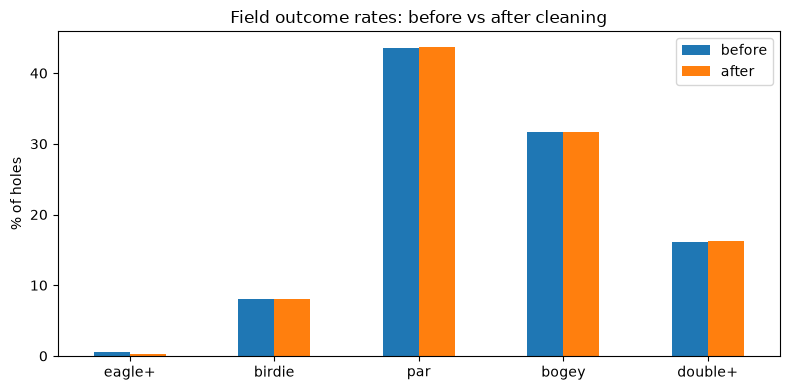

In [5]:
# ---- Validation: prove the cleaning removed artifacts WITHOUT shifting the real signal ----
after_summary = scoring_summary(d3_data)

print("Field outcome rates (%)   [pp = percentage-point change]")
rates = pd.concat([before_summary["outcome_rates"], after_summary["outcome_rates"]], axis=1)
rates.columns = ["before", "after"]
rates["pp_change"] = (rates["after"] - rates["before"]).round(3)
print(rates.to_string(), "\n")

print("Mean to-par by par   (par 36 summary rows gone; std tightens as junk scores leave)")
by_par = pd.concat({"before_mean": before_summary["by_par"]["mean"],
                    "after_mean":  after_summary["by_par"]["mean"],
                    "before_std":  before_summary["by_par"]["std"],
                    "after_std":   after_summary["by_par"]["std"]}, axis=1)
print(by_par.to_string(), "\n")

print("18-hole round to-par   (impossible max collapses; mean/median hold)")
rnd = pd.concat({"before": before_summary["round"], "after": after_summary["round"]}, axis=1)
print(rnd.to_string())

# Visual: real outcomes are unchanged, the "eagle+" artifact is corrected
fig, ax = plt.subplots(figsize=(8, 4))
rates[["before", "after"]].plot(kind="bar", ax=ax)
ax.set_title("Field outcome rates: before vs after cleaning")
ax.set_ylabel("% of holes"); ax.set_xlabel("")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()


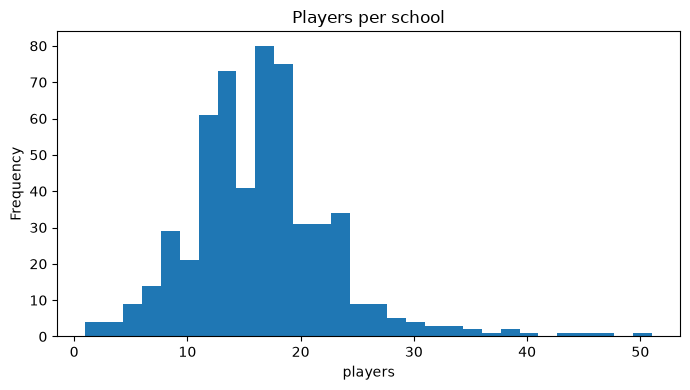

In [6]:
d3 = d3_data.query("tournament_level == 'TOURNAMENT'").copy()

# players per school
fig, ax = plt.subplots(figsize=(7, 4))
d3.groupby("school_id")["player_id"].nunique().plot(kind="hist", bins=30, ax=ax)
ax.set_title("Players per school"); ax.set_xlabel("players")
plt.tight_layout(); plt.show()

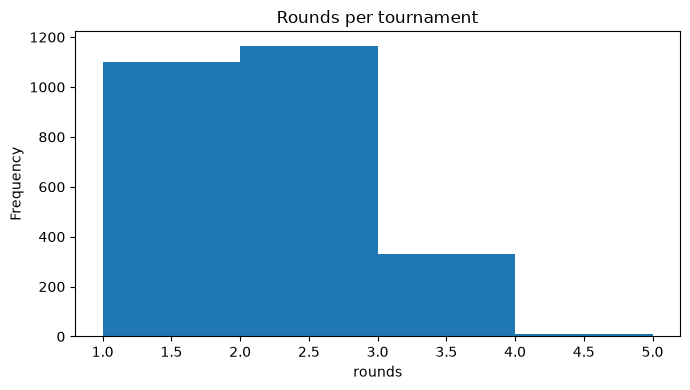

In [7]:
# rounds per tournament
fig, ax = plt.subplots(figsize=(7, 4))
rpt = d3.groupby("tournament_id")["round_number"].nunique()
rpt.plot(kind="hist", bins=range(1, rpt.max() + 2), ax=ax)
ax.set_title("Rounds per tournament"); ax.set_xlabel("rounds")
plt.tight_layout(); plt.show()

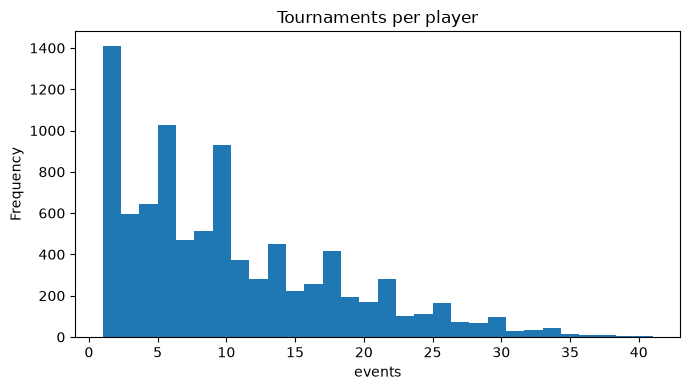

In [8]:
# tournaments per player (workload / sample size per player)
fig, ax = plt.subplots(figsize=(7, 4))
epp = d3.groupby("player_id")["tournament_id"].nunique()
epp.plot(kind="hist", bins=30, ax=ax)
ax.set_title("Tournaments per player"); ax.set_xlabel("events")
plt.tight_layout(); plt.show()

In [9]:
def add_outcomes(df):
    df = df.copy()
    d = df["to_par"]
    df["outcome"] = np.select(
        [d <= -2, d == -1, d == 0, d == 1, d >= 2],
        ["eagle+", "birdie", "par", "bogey", "double+"],
        default="other")
    return df

d3 = add_outcomes(d3)

order = ["eagle+","birdie","par","bogey","double+"]
rates = (d3["outcome"].value_counts(normalize=True)
         .reindex(order) * 100).round(2)
print("Field outcome rates (%):"); print(rates)

Field outcome rates (%):
outcome
eagle+      0.23
birdie      8.05
par        43.61
bogey      31.78
double+    16.33
Name: proportion, dtype: float64


## Hole-level strokes gained, and its carry-over to the next hole

**Idea.** For every hole actually played, compare a player's score to what the *field* shot on that
same hole under the same conditions (same tournament, same round, same course, same hole number).
The field mean is our "expected" score; beating it is positive strokes gained (SG).

Then we look one hole ahead — *within the same round only* — to ask a simple momentum question:
**does gaining strokes on a hole tell us anything about the next hole?**

Definitions:
- `field_avg` = mean `score` over `(tournament_id, round_number, hole_number)` — the field on that
  hole that round. (We deliberately leave `course_id` out of the key: it is fully missing for 416
  tournaments, and each tournament-round is a single course anyway, so keying on it would only drop
  16.5% of rows to NaN for no gain.)
- `sg = field_avg - score`  (positive = better than the field)
- `sg_next` / `score_next` = the same player's values on the **immediately following hole** in that
  round. We only count it as a valid "next" hole when it is literally `hole_number + 1`, so we never
  wrap 18 -> 1 or bleed from one round into the next.

In [10]:
# ---- Step 1: field average per hole  ->  strokes gained on that hole ----
# NB: course_id is NOT in the key. It is NaN for 416 whole tournaments (16.5% of rows),
# and every tournament-round maps to exactly one course anyway, so including it only threw
# those rows out of the groupby (-> NaN field_avg/sg). tournament+round+hole is the field.
HOLE_KEYS = ["tournament_id", "round_number", "hole_number"]
ROUND_KEYS = ["tournament_id", "round_number", "player_id"]


def add_strokes_gained(df):
    """SG on a hole = (field mean score on that exact hole) - (player's score)."""
    df = df.copy()
    g = df.groupby(HOLE_KEYS)["score"]
    df["field_avg"]  = g.transform("mean")   # expected score for this hole/round/course
    df["field_size"] = g.transform("size")   # how many players make up that field mean
    df["sg"] = df["field_avg"] - df["score"]
    return df


# ---- Step 2: the SAME player's next hole in the SAME round (lead), no wrap-around ----
def add_next_hole(df):
    """Add sg_next / score_next via a within-round lead, valid only when it's hole n -> n+1."""
    df = df.sort_values(ROUND_KEYS + ["hole_number"]).copy()
    g = df.groupby(ROUND_KEYS, sort=False)
    df["sg_next"]    = g["sg"].shift(-1)          # pandas' lead == shift(-1)
    df["score_next"] = g["score"].shift(-1)
    nxt_hole         = g["hole_number"].shift(-1)
    # only a real "next hole" if it is the immediately following number in the same round;
    # this drops round-to-round wraps AND the 18 -> 1 wrap, plus any gaps from dropped rows.
    valid = nxt_hole == df["hole_number"] + 1
    df.loc[~valid, ["sg_next", "score_next"]] = np.nan
    return df


d3 = add_next_hole(add_strokes_gained(d3))

# season key: calendar year of the tournament -> baseline for the skill control later
d3["year"] = pd.to_datetime(d3["tournament_start_date"], errors="coerce").dt.year

# sanity checks
pair = d3.dropna(subset=["sg", "sg_next"])
print(f"holes with a valid next hole: {len(pair):,} of {len(d3):,} "
      f"({len(pair)/len(d3)*100:.1f}%)")
print(f"mean SG (should be ~0 by construction): {d3['sg'].mean():+.4f}")
print(f"mean field size per hole: {d3['field_size'].mean():.0f} players")
d3[["hole_number", "score", "field_avg", "sg", "score_next", "sg_next"]].head(8).round(3)

holes with a valid next hole: 2,808,845 of 2,974,607 (94.4%)
mean SG (should be ~0 by construction): -0.0000
mean field size per hole: 63 players


,hole_number,score,field_avg,sg,score_next,sg_next
18,1,4,4.286,0.286,5.0,0.571
19,2,5,5.571,0.571,4.0,1.000
20,3,4,5.000,1.000,6.0,-1.143
21,4,6,4.857,-1.143,3.0,0.000
22,5,3,3.000,0.000,6.0,-2.000
23,6,6,4.000,-2.000,5.0,-0.429
24,7,5,4.571,-0.429,3.0,0.571
25,8,3,3.571,0.571,4.0,0.000


In [11]:
# ---- Rudimentary EDA: does SG on a hole carry over to the next hole? ----
pair = d3.dropna(subset=["sg", "sg_next"]).copy()
x, y = pair["sg"].to_numpy(), pair["sg_next"].to_numpy()

r = np.corrcoef(x, y)[0, 1]
slope, intercept, _, p_value, _ = stats.linregress(x, y)
print(f"n pairs          : {len(pair):,}")
print(f"corr(sg, sg_next): {r:+.4f}   (p = {p_value:.2e})")
print(f"OLS slope        : {slope:+.4f}  -> +1 stroke gained now predicts {slope:+.3f} SG next hole")

# Binned view: average next-hole SG for buckets of this-hole SG (the clearest read of the effect)
bins = [-np.inf, -2, -1, -0.5, 0.5, 1, 2, np.inf]
labels = ["<=-2", "-2..-1", "-1..-.5", "~0 (~par vs field)", ".5..1", "1..2", ">=2"]
pair["sg_bin"] = pd.cut(pair["sg"], bins=bins, labels=labels)
binned = pair.groupby("sg_bin", observed=True)["sg_next"].agg(["mean", "count"])
print("\nMean next-hole SG by this-hole SG bucket:")
print(binned.round(4).to_string())

n pairs          : 2,808,845
corr(sg, sg_next): +0.1849   (p = 0.00e+00)
OLS slope        : +0.1853  -> +1 stroke gained now predicts +0.185 SG next hole

Mean next-hole SG by this-hole SG bucket:
                      mean    count
sg_bin                             
<=-2               -0.6536    92461
-2..-1             -0.2335   257104
-1..-.5            -0.0859   366671
~0 (~par vs field)  0.0199  1271629
.5..1               0.1146   519643
1..2                0.2084   285127
>=2                 0.4761    16210


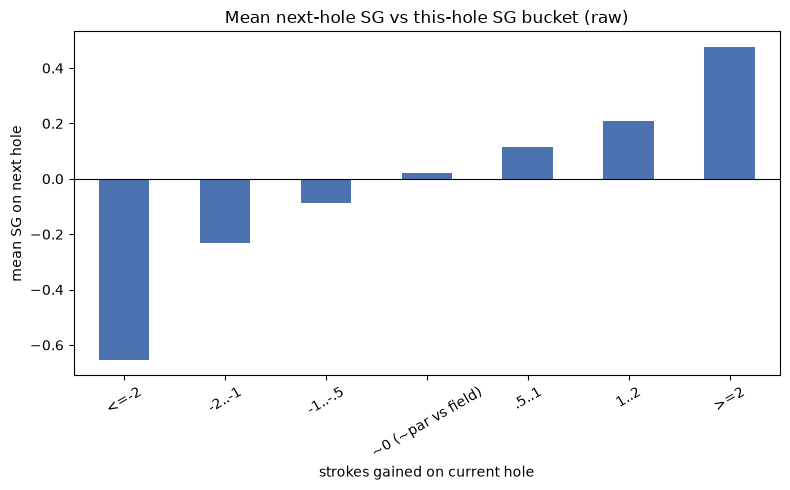

In [12]:
# Graph: mean next-hole SG by this-hole SG bucket (the headline read, raw / uncontrolled)
fig, ax = plt.subplots(figsize=(8, 5))
binned["mean"].plot(kind="bar", ax=ax, color="#4c72b0")
ax.axhline(0, color="k", lw=0.8)
ax.set_title("Mean next-hole SG vs this-hole SG bucket (raw)")
ax.set_xlabel("strokes gained on current hole"); ax.set_ylabel("mean SG on next hole")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

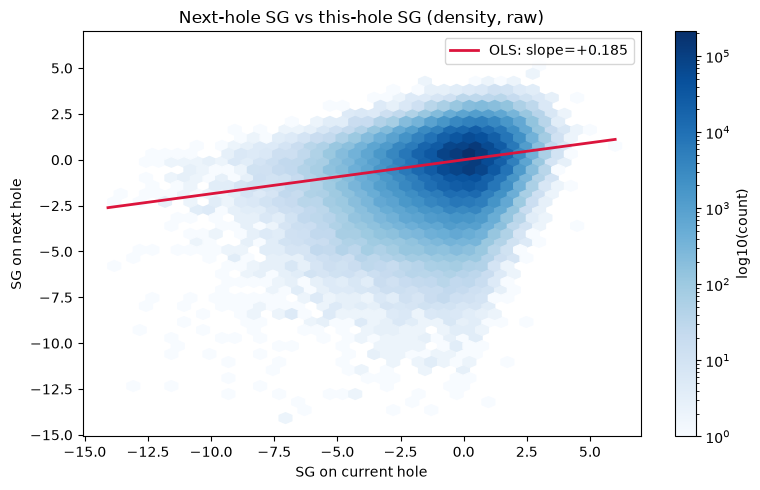

In [13]:
# Graph: density of (this-hole SG, next-hole SG) with the OLS fit
fig, ax = plt.subplots(figsize=(8, 5))
hb = ax.hexbin(x, y, gridsize=40, cmap="Blues", mincnt=1, bins="log")
xs = np.linspace(x.min(), x.max(), 100)
ax.plot(xs, intercept + slope * xs, color="crimson", lw=2, label=f"OLS: slope={slope:+.3f}")
ax.set_title("Next-hole SG vs this-hole SG (density, raw)")
ax.set_xlabel("SG on current hole"); ax.set_ylabel("SG on next hole")
ax.legend(loc="upper right")
fig.colorbar(hb, ax=ax, label="log10(count)")
plt.tight_layout(); plt.show()

### Controlling for player quality: subtract each player's *season* average

The raw +0.18 could just be **skill** — good players beat the field on both holes, so consecutive-hole
SG looks correlated even with zero momentum. To strip that out we subtract a player's own baseline SG
and re-run the identical correlation on the residual.

**Which baseline?** *Not* the round mean: the two holes we're comparing are themselves part of that
round, so the round average is contaminated by the very values we're studying (it would mechanically
manufacture a negative correlation). Instead we use each player's **season** baseline — their average
SG per hole across **every tournament that calendar year**. That captures "how good was this player
this season" without peeking at the specific round in question.

In [14]:
# ---- Control for skill using each player's SEASON (player x year) average SG per hole ----
# Baseline = mean SG over ALL that player's holes in that calendar year's tournaments.
d3["sg_season_mean"] = d3.groupby(["player_id", "year"])["sg"].transform("mean")

# residualize the current AND next hole by the SAME season baseline (next hole = same player/year)
d3["sg_r"]      = d3["sg"]      - d3["sg_season_mean"]
d3["sg_next_r"] = d3["sg_next"] - d3["sg_season_mean"]


def corr_slope(df, xcol, ycol):
    s = df.dropna(subset=[xcol, ycol])
    xx, yy = s[xcol].to_numpy(), s[ycol].to_numpy()
    lr = stats.linregress(xx, yy)
    return {"corr": np.corrcoef(xx, yy)[0, 1], "slope": lr.slope, "p": lr.pvalue, "n": len(s)}

results = pd.DataFrame({
    "raw (skill NOT removed)":    corr_slope(d3, "sg",   "sg_next"),
    "minus player-season mean":   corr_slope(d3, "sg_r", "sg_next_r"),
}).T
print("Carry-over of SG to the next hole, before vs after removing season-level skill:\n")
print(results.assign(n=results["n"].astype(int)).round(4).to_string())

Carry-over of SG to the next hole, before vs after removing season-level skill:

                            corr   slope    p        n
raw (skill NOT removed)   0.1849  0.1853  0.0  2808845
minus player-season mean  0.0432  0.0433  0.0  2808845


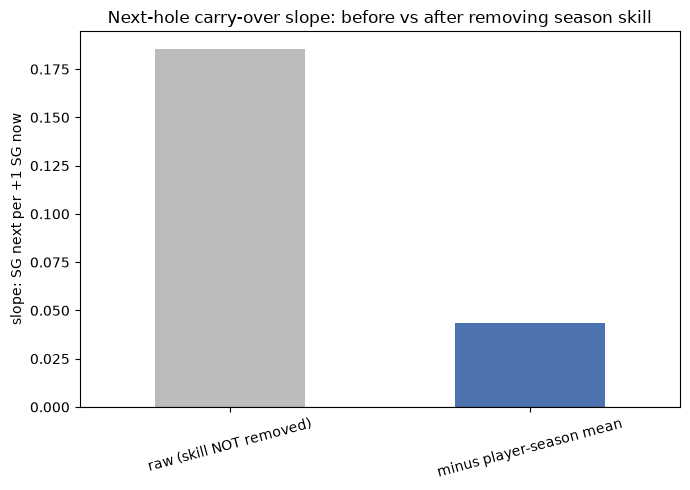

In [15]:
# Graph: carry-over slope, raw vs after removing season skill
fig, ax = plt.subplots(figsize=(7, 5))
results["slope"].plot(kind="bar", ax=ax, color=["#bbbbbb", "#4c72b0"])
ax.axhline(0, color="k", lw=0.8)
ax.set_title("Next-hole carry-over slope: before vs after removing season skill")
ax.set_ylabel("slope: SG next per +1 SG now"); ax.set_xlabel("")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

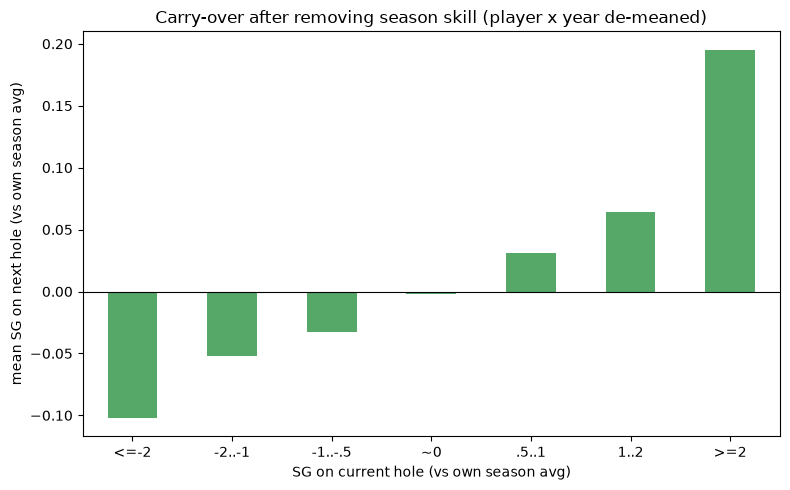

In [16]:
# Graph: season-residual binned means -> the skill-controlled carry-over
bins = [-np.inf, -2, -1, -0.5, 0.5, 1, 2, np.inf]
labels = ["<=-2", "-2..-1", "-1..-.5", "~0", ".5..1", "1..2", ">=2"]
res = d3.dropna(subset=["sg_r", "sg_next_r"]).copy()
res["sg_bin"] = pd.cut(res["sg_r"], bins=bins, labels=labels)
binned_r = res.groupby("sg_bin", observed=True)["sg_next_r"].mean()

fig, ax = plt.subplots(figsize=(8, 5))
binned_r.plot(kind="bar", ax=ax, color="#55a868")
ax.axhline(0, color="k", lw=0.8)
ax.set_title("Carry-over after removing season skill (player x year de-meaned)")
ax.set_xlabel("SG on current hole (vs own season avg)")
ax.set_ylabel("mean SG on next hole (vs own season avg)")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()